# VAE: Auto-Encoding Variational Bayes (Kingma & Welling, 2013)

A plain [autoencoder](/how-models-work/autoencoders/) compresses data through a
bottleneck, but its codes are scattered wherever training put them. Pick a
random point in its latent space, decode it, and you usually get garbage. It is
a compressor, not a **generative model**.

The variational autoencoder makes the latent space a probability distribution
you can sample from. It does that with two ideas from this paper:

1. **The evidence lower bound (ELBO)**: a trainable objective that bounds the
   likelihood $\log p(x)$, which cannot be computed directly.
2. **The reparameterisation trick**: rewrite sampling so gradients can flow
   through it, and the whole thing trains with ordinary backpropagation.

This page verifies the ELBO identity exactly on a model where $\log p(x)$ is
known, measures why the reparameterisation trick matters, and trains a VAE on
handwritten digits, then walks through its latent space.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from hmw_motion import Scene, mix

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)
np.set_printoptions(precision=4, suppress=True, linewidth=120)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


def npdf(x, m, v):
    return np.exp(-(x - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v)


print("helpers ready")

helpers ready


## 1. The ELBO, and why it is a bound

A latent-variable model says: draw a code $z \sim p(z) = \mathcal{N}(0, I)$, then
draw data from a decoder $p_\theta(x \mid z)$. Training should maximise

$$\log p_\theta(x) = \log \int p_\theta(x \mid z)\, p(z)\, dz,$$

but that integral over every possible $z$ is intractable for a neural decoder.
The VAE introduces an **encoder** $q_\phi(z \mid x)$ that guesses which codes
could have produced $x$. Then, exactly:

$$\log p_\theta(x) = \underbrace{\mathbb{E}_{q}\big[\log p_\theta(x\mid z)\big] - \mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{ELBO}} \;+\; \mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p_\theta(z\mid x)\big)$$

The last KL is never negative, so the ELBO is a lower bound on $\log p(x)$. The
gap is exactly how far the encoder is from the true posterior. Maximising the
ELBO therefore does two jobs at once: it fits the decoder and it pulls the
encoder toward the posterior.

The two ELBO terms read naturally: **reconstruct $x$ well**, and **keep the
codes close to the prior** so that sampling from $\mathcal{N}(0, I)$ lands
somewhere the decoder understands.

### Checking it where everything is computable

Use a 1-D linear-Gaussian model: $z \sim \mathcal{N}(0,1)$ and
$x \mid z \sim \mathcal{N}(wz, s^2)$. Then $p(x) = \mathcal{N}(0, w^2+s^2)$ and the
true posterior is Gaussian too, so every term above has a closed form.

In [2]:
banner("THE ELBO IDENTITY, CHECKED EXACTLY")
w, s2, x = 2.0, 0.5, 1.5
log_px = np.log(npdf(x, 0, w ** 2 + s2))
post_v = s2 / (w ** 2 + s2)
post_m = w * x / (w ** 2 + s2)
print(f"  model: z ~ N(0,1), x|z ~ N({w} z, {s2});  observed x = {x}")
print(f"  log p(x) = log N({x}; 0, {w**2 + s2}) = {log_px:.6f}")
print(f"  true posterior p(z|x) = N({post_m:.4f}, {post_v:.4f})")


def elbo(m, v):
    rec = -0.5 * np.log(2 * np.pi * s2) - ((x - w * m) ** 2 + w ** 2 * v) / (2 * s2)
    kl_prior = 0.5 * (v + m ** 2 - 1 - np.log(v))
    return rec, kl_prior, rec - kl_prior


def kl_gauss(m1, v1, m2, v2):
    return 0.5 * (np.log(v2 / v1) + (v1 + (m1 - m2) ** 2) / v2 - 1)


step("Several encoders q(z|x) = N(m, v)")
print(f"  {'m':>6} {'v':>6} | {'recon':>9} {'KL(q||prior)':>13} {'ELBO':>9} | {'gap':>8} {'KL(q||post)':>12}")
worst = 0
for m, v in [(0.0, 1.0), (0.3, 0.5), (0.9, 0.2), (post_m, post_v)]:
    rec, klp, el = elbo(m, v)
    gap = log_px - el
    klq = kl_gauss(m, v, post_m, post_v)
    worst = max(worst, abs(gap - klq))
    print(f"  {m:6.3f} {v:6.3f} | {rec:9.4f} {klp:13.4f} {el:9.4f} | {gap:8.5f} {klq:12.5f}")
check("log p(x) - ELBO == KL(q || true posterior) for every q (to 1e-12)", worst < 1e-12)
check("the bound is tight (gap 0) exactly when q is the true posterior",
      abs(log_px - elbo(post_m, post_v)[2]) < 1e-12)

rng = np.random.default_rng(0)
zs = rng.normal(0.3, np.sqrt(0.5), 400_000)
mc_rec = np.mean(-0.5 * np.log(2 * np.pi * s2) - (x - w * zs) ** 2 / (2 * s2))
print(f"\n  Monte Carlo check of the reconstruction term for q = N(0.3, 0.5): "
      f"{mc_rec:.4f} vs closed form {elbo(0.3, 0.5)[0]:.4f}")

  THE ELBO IDENTITY, CHECKED EXACTLY
  model: z ~ N(0,1), x|z ~ N(2.0 z, 0.5);  observed x = 1.5
  log p(x) = log N(1.5; 0, 4.5) = -1.920977
  true posterior p(z|x) = N(0.6667, 0.1111)

Several encoders q(z|x) = N(m, v)
------------------------------------------------------------------------------
       m      v |     recon  KL(q||prior)      ELBO |      gap  KL(q||post)
   0.000  1.000 |   -6.8224        0.0000   -6.8224 |  4.90139      4.90139
   0.300  0.500 |   -3.3824        0.1416   -3.5239 |  1.60296      1.60296
   0.900  0.200 |   -1.4624        0.8097   -2.2721 |  0.35111      0.35111
   0.667  0.111 |   -1.0446        0.8764   -1.9210 |  0.00000      0.00000
  [PASS] log p(x) - ELBO == KL(q || true posterior) for every q (to 1e-12)
  [PASS] the bound is tight (gap 0) exactly when q is the true posterior

  Monte Carlo check of the reconstruction term for q = N(0.3, 0.5): -3.3875 vs closed form -3.3824


Training the encoder means moving $q$ toward the posterior. As it moves, the
ELBO rises to meet $\log p(x)$, and the gap, the KL to the posterior, closes.

In [3]:
def elbo_scene():
    sc = Scene(720, 380, dur=9.0, caption="Moving q(z|x) toward the true posterior closes the gap to log p(x)",
               poster=8.5)
    X0, X1, Y0 = 40, 440, 300
    zgrid = np.linspace(-2.5, 3.0, 90)
    px = lambda zz: X0 + (zz + 2.5) / 5.5 * (X1 - X0)
    sc.line(X0, Y0, X1, Y0, stroke="grid", sw=1.5)
    for zt in [-2, -1, 0, 1, 2, 3]:
        sc.text(px(zt), Y0 + 16, str(zt), size=11, fill="muted")
    sc.text((X0 + X1) / 2, Y0 + 36, "z", size=12, fill="muted")
    yscale = 230
    post_pts = []
    for zz in zgrid:
        post_pts += [px(zz), Y0 - npdf(zz, post_m, post_v) * yscale]
    sc.poly(post_pts, stroke="green", sw=3)
    sc.text(px(post_m) + 40, Y0 - npdf(post_m, post_m, post_v) * yscale - 6, "true posterior", size=12,
            fill="green", anchor="start")
    path = [(0.0, 1.0), (0.25, 0.7), (0.5, 0.45), (0.8, 0.28), (1.1, 0.16), (post_m, post_v)]

    def qpts(m, v):
        out = []
        for zz in zgrid:
            out += [px(zz), Y0 - npdf(zz, m, v) * yscale]
        return out

    q_ = sc.poly(qpts(*path[0]), stroke="cyan", sw=3, fill="#22d3ee22", closed=False)
    ql = sc.text(px(path[0][0]), Y0 - npdf(0, 0, 1) * yscale - 14, "q(z|x)", size=12, fill="cyan")
    # right panel: ELBO bar vs log p(x)
    BX, BY0 = 560, 320
    vmin = -6.0
    ph = lambda val: (val - vmin) / (0 - vmin) * 260
    sc.line(BX - 50, BY0 - ph(log_px), BX + 90, BY0 - ph(log_px), stroke="amber", sw=2, dash="6 4")
    sc.text(BX + 94, BY0 - ph(log_px), "log p(x)", size=12, fill="amber", anchor="start")
    e0 = elbo(*path[0])[2]
    bar = sc.rect(BX - 30, BY0 - ph(e0), 60, ph(e0), fill="violet", rx=4)
    en = sc.num(BX, BY0 + 18, e0, dec=3, pre="ELBO ", size=13, fill="violet")
    gap = sc.num(BX, 40, log_px - e0, dec=3, pre="gap = KL(q||post) = ", size=13, fill="text")
    t = 0.8
    for (m, v) in path[1:]:
        e = elbo(m, v)[2]
        q_.to(t, t + 1.1, pts=qpts(m, v))
        ql.to(t, t + 1.1, x=px(m), y=Y0 - npdf(m, m, v) * yscale - 14)
        bar.to(t, t + 1.1, y=BY0 - ph(e), h=ph(e))
        en.to(t, t + 1.1, v=e)
        gap.to(t, t + 1.1, v=log_px - e)
        t += 1.4
    sc.beat(0.0, "Start with q = the prior N(0, 1): a poor guess about which z produced this x.")
    sc.beat(0.8, "Move q's mean and variance toward the posterior: the ELBO (violet) rises.")
    sc.beat(6.4, "When q equals the posterior the gap is zero: the ELBO equals log p(x).")
    return sc

elbo_scene()

<motion scene: Moving q(z|x) toward the true posterior closes the gap to log p(x) (17 elements, 9s)>

## 2. The reparameterisation trick

The ELBO contains $\mathbb{E}_{z \sim q_\phi}[\cdot]$, and the encoder parameters
$\phi$ sit inside the *distribution being sampled*. You cannot backpropagate
through "draw a random number".

The trick is to move the randomness outside:

$$z = \mu_\phi(x) + \sigma_\phi(x)\odot\varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I)$$

Now $z$ is a deterministic, differentiable function of $\mu$ and $\sigma$, and
$\varepsilon$ is just an input. Gradients flow through $\mu$ and $\sigma$ as
through any layer.

The alternative, the score-function (REINFORCE) estimator, is also unbiased.
The cell below measures what that costs in variance on a simple case:
$\frac{\partial}{\partial\mu}\mathbb{E}_{z\sim\mathcal{N}(\mu,\sigma^2)}[z^2] = 2\mu$.

In [4]:
banner("TWO UNBIASED GRADIENT ESTIMATORS, VERY DIFFERENT NOISE")
mu, sig = 1.0, 1.0
eps = rng.standard_normal(1_000_000)
z = mu + sig * eps
reparam = 2 * z                           # d/dmu of (mu + sig*eps)^2
score = z ** 2 * (z - mu) / sig ** 2      # f(z) * d/dmu log q(z)
print(f"  true gradient: 2 * mu = {2*mu:.3f}")
print(f"  reparameterisation:  mean {reparam.mean():.4f}   variance {reparam.var():8.3f}")
print(f"  score function:      mean {score.mean():.4f}   variance {score.var():8.3f}")
print(f"  variance ratio: {score.var()/reparam.var():.1f}x")
check("both are unbiased (means within 0.02 of 2.0)", abs(reparam.mean() - 2) < .02 and abs(score.mean() - 2) < .02)
check("reparameterisation has at least 5x lower variance", score.var() > 5 * reparam.var())

  TWO UNBIASED GRADIENT ESTIMATORS, VERY DIFFERENT NOISE
  true gradient: 2 * mu = 2.000
  reparameterisation:  mean 2.0009   variance    3.992
  score function:      mean 1.9994   variance   30.037
  variance ratio: 7.5x
  [PASS] both are unbiased (means within 0.02 of 2.0)
  [PASS] reparameterisation has at least 5x lower variance


In [5]:
def reparam_scene():
    sc = Scene(720, 360, dur=10.0, caption="z = mu + sigma * eps: the noise is an input, so gradients reach mu and sigma",
               poster=9.0)
    eps_s = np.random.default_rng(3).standard_normal(40)
    L0, R0 = 120, 560
    sc.text(L0, 40, "eps ~ N(0, 1)", size=14, fill="muted", weight=700)
    sc.text(R0, 40, "z = mu + sigma * eps", size=14, fill="cyan", weight=700)
    ax = lambda c, v: c + v * 33
    for c in (L0, R0):
        sc.line(c - 150, 300, c + 150, 300, stroke="grid", sw=1.5)
    for k in (-4, -3, -2, -1, 0, 1, 2, 3, 4):
        sc.text(ax(L0, k), 318, str(k), size=10, fill="muted")
        sc.text(ax(R0, k), 318, str(k), size=10, fill="muted")
    mus, sigs = [0.0, 1.5, 1.5, -1.0], [1.0, 1.0, 0.4, 0.7]
    dots = []
    for i, e in enumerate(eps_s):
        y = 100 + (i % 10) * 18
        sc.circle(ax(L0, e), y, r=4, fill="muted")
        dots.append(sc.circle(ax(R0, mus[0] + sigs[0] * e), y, r=4, fill="cyan", opacity=0.9))
    mtxt = sc.num(R0 - 60, 70, mus[0], dec=1, pre="mu = ", size=13, fill="amber")
    stxt = sc.num(R0 + 60, 70, sigs[0], dec=1, pre="sigma = ", size=13, fill="pink")
    t = 1.5
    for m, sg in zip(mus[1:], sigs[1:]):
        for i, e in enumerate(eps_s):
            dots[i].to(t, t + 1.2, cx=ax(R0, m + sg * e))
        mtxt.to(t, t + 1.2, v=m); stxt.to(t, t + 1.2, v=sg)
        t += 2.6
    sc.arrow(L0 + 175, 190, R0 - 175, 190, stroke="text", sw=2, head=10)
    sc.text(360, 176, "shift by mu, scale by sigma", size=12, fill="text")
    sc.text(360, 210, "differentiable in mu and sigma", size=11, fill="green")
    sc.beat(0.0, "The same 40 noise samples on the left are reused in every frame.")
    sc.beat(1.5, "Change mu and the whole cloud shifts: dz/dmu = 1 for every sample.")
    sc.beat(4.1, "Change sigma and it stretches: dz/dsigma = eps. Both are ordinary derivatives.")
    sc.beat(6.7, "Nothing random sits between the loss and the encoder's outputs any more.")
    return sc

reparam_scene()

<motion scene: z = mu + sigma * eps: the noise is an input, so gradients reach mu and sigma (107 elements, 10s)>

## 3. A VAE on handwritten digits

The encoder maps each 8×8 digit to $(\mu, \log\sigma^2)$ in a **2-dimensional**
latent space, small enough to draw. The decoder maps $z$ back to 64 pixel
intensities. The loss is the negative ELBO: binary cross-entropy for
reconstruction, plus the closed-form KL between $\mathcal{N}(\mu, \sigma^2)$
and $\mathcal{N}(0, 1)$:

$$\mathrm{KL} = -\tfrac{1}{2}\sum_j \big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big)$$

  TRAINING A 2-D VAE ON 1,797 DIGITS
  step     1: reconstruction  44.34   KL  0.01   -ELBO  44.35 nats
  step   500: reconstruction  22.18   KL  2.29   -ELBO  24.47 nats
  step  2000: reconstruction  20.15   KL  3.26   -ELBO  23.41 nats
  step  6000: reconstruction  19.39   KL  3.45   -ELBO  22.84 nats

KL term: closed form vs Monte Carlo, on the trained encoder
------------------------------------------------------------------------------
  mean KL over 200 digits: closed form 3.4551   Monte Carlo 3.4551
  [PASS] closed-form KL matches a 20,000-sample estimate (within 1%)


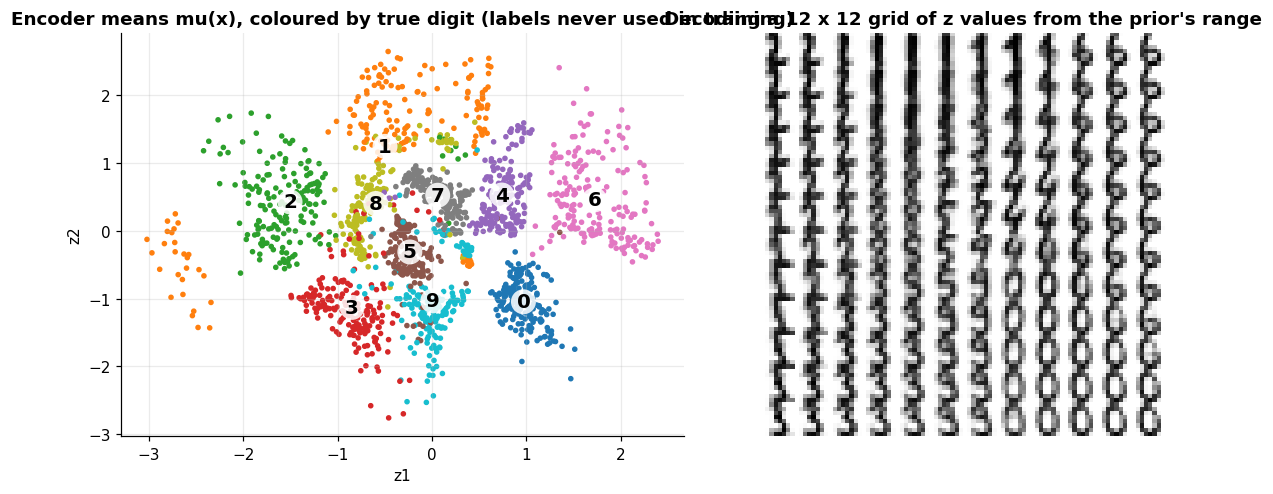

In [6]:
banner("TRAINING A 2-D VAE ON 1,797 DIGITS")
dg = load_digits()
X = torch.tensor(dg.data / 16.0, dtype=torch.float32); y = dg.target


class VAE(nn.Module):
    def __init__(self, zd=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU())
        self.mu, self.lv = nn.Linear(128, zd), nn.Linear(128, zd)
        self.dec = nn.Sequential(nn.Linear(zd, 128), nn.ReLU(), nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 64))

    def encode(self, x):
        h = self.enc(x)
        return self.mu(h), self.lv(h)

    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.exp(0.5 * lv) * torch.randn_like(mu)        # reparameterisation
        return self.dec(z), mu, lv


vae = VAE()
opt = torch.optim.Adam(vae.parameters(), lr=2e-3)
log = []
for it in range(1, 6001):
    idx = torch.randint(0, len(X), (128,))
    logits, mu, lv = vae(X[idx])
    rec = F.binary_cross_entropy_with_logits(logits, X[idx], reduction="sum") / len(idx)
    kl = (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1)).mean()
    loss = rec + kl
    opt.zero_grad(); loss.backward(); opt.step()
    if it in (1, 500, 2000, 6000):
        print(f"  step {it:>5}: reconstruction {rec.item():6.2f}   KL {kl.item():5.2f}   -ELBO {loss.item():6.2f} nats")

vae.eval()
with torch.no_grad():
    mu_all, lv_all = vae.encode(X)
step("KL term: closed form vs Monte Carlo, on the trained encoder")
with torch.no_grad():
    m0, v0 = mu_all[:200], lv_all[:200].exp()
    kl_cf = (-0.5 * (1 + v0.log() - m0 ** 2 - v0)).sum(1)
    zz = m0 + v0.sqrt() * torch.randn(20000, 200, 2)
    logq = (-0.5 * ((zz - m0) ** 2 / v0 + v0.log() + np.log(2 * np.pi))).sum(-1)
    logp = (-0.5 * (zz ** 2 + np.log(2 * np.pi))).sum(-1)
    kl_mc = (logq - logp).mean(0)
print(f"  mean KL over 200 digits: closed form {kl_cf.mean():.4f}   Monte Carlo {kl_mc.mean():.4f}")
check("closed-form KL matches a 20,000-sample estimate (within 1%)",
      abs(kl_cf.mean() - kl_mc.mean()) / kl_cf.mean() < 0.01)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
mu_np = mu_all.numpy()
sca = axes[0].scatter(mu_np[:, 0], mu_np[:, 1], c=y, cmap="tab10", s=7)
for d in range(10):
    c = mu_np[y == d].mean(0)
    axes[0].text(c[0], c[1], str(d), fontsize=13, weight="bold", ha="center", va="center",
                 bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="none", alpha=0.85))
axes[0].set_title("Encoder means mu(x), coloured by true digit (labels never used in training)")
axes[0].set_xlabel("z1"); axes[0].set_ylabel("z2")
grid = np.linspace(-2.2, 2.2, 12)
canvas = np.zeros((12 * 8, 12 * 8))
with torch.no_grad():
    for i, z2 in enumerate(grid[::-1]):
        for j, z1 in enumerate(grid):
            zt = torch.tensor([[z1, z2]], dtype=torch.float32)
            canvas[i * 8:(i + 1) * 8, j * 8:(j + 1) * 8] = torch.sigmoid(vae.dec(zt)).view(8, 8)
axes[1].imshow(canvas, cmap="gray_r"); axes[1].axis("off")
axes[1].set_title("Decoding a 12 x 12 grid of z values from the prior's range")
fig.tight_layout()

Two things to notice. The digits form clusters even though the VAE never saw a
label: it organised the latent space by visual similarity on its own. And the
decoded grid is smooth. Every point in the prior's range decodes to something
digit-like, with gradual transitions between classes. That is the KL term at
work. It packs the codes together near the origin, with no empty gaps where the
decoder has never been trained.

A walk through the latent space, decoded at every step:

In [7]:
def walk_scene():
    cents = {d: mu_np[y == d].mean(0) for d in range(10)}
    route = [0, 6, 5, 9, 7, 1, 4, 0]
    pts_ = []
    for a, b in zip(route[:-1], route[1:]):
        for u in np.linspace(0, 1, 9)[:-1]:
            pts_.append((1 - u) * cents[a] + u * cents[b])
    pts_.append(cents[route[-1]])
    sc = Scene(720, 380, dur=0.6 + len(pts_) * 0.22 + 0.5,
               caption="Walking the 2-D latent space of the trained VAE and decoding every point",
               poster=0.6 + 30 * 0.22)
    lo, hi = mu_np.min(0), mu_np.max(0)
    to = lambda p: (40 + (p[0] - lo[0]) / (hi[0] - lo[0]) * 320, 350 - (p[1] - lo[1]) / (hi[1] - lo[1]) * 300)
    cols = ["#22d3ee", "#a78bfa", "#f472b6", "#fbbf24", "#34d399", "#f87171", "#60a5fa", "#e879f9", "#a3e635", "#fb923c"]
    sub = np.random.default_rng(0).choice(len(mu_np), 450, replace=False)
    for i in sub:
        x_, y_ = to(mu_np[i])
        sc.circle(x_, y_, r=2.2, fill=cols[y[i]], opacity=0.55)
    for d in range(10):
        x_, y_ = to(cents[d])
        sc.text(x_, y_, str(d), size=15, fill="white", weight=700)
    cur = sc.circle(*to(pts_[0]), r=8, fill="amber", stroke="white", sw=2)
    cs = 32
    ox, oy = 430, 70
    sc.text(ox + 4 * cs, 46, "decoder output", size=13, fill="muted")
    with torch.no_grad():
        imgs = [torch.sigmoid(vae.dec(torch.tensor(p[None], dtype=torch.float32))).view(8, 8).numpy() for p in pts_]
    cells = [[sc.rect(ox + j * cs, oy + i * cs, cs - 2, cs - 2, fill=mix("bg", "white", imgs[0][i, j]), rx=3)
              for j in range(8)] for i in range(8)]
    zlab = sc.text(ox + 4 * cs, oy + 8 * cs + 26, "", size=12, fill="amber", mono=True)
    for k in range(1, len(pts_)):
        t0, t1 = 0.6 + (k - 1) * 0.22, 0.6 + k * 0.22
        x_, y_ = to(pts_[k])
        cur.to(t0, t1, cx=x_, cy=y_, ease="lin")
        for i in range(8):
            for j in range(8):
                cells[i][j].to(t0, t1, fill=mix("bg", "white", imgs[k][i, j]), ease="lin")
        zlab.set(t1, s=f"z = ({pts_[k][0]:+.2f}, {pts_[k][1]:+.2f})")
    sc.beat(0.0, "Left: where the encoder puts each digit. Right: what the decoder makes of the amber point.")
    sc.beat(3.0, "Between two clusters the decoder morphs smoothly from one digit into the next.")
    return sc

walk_scene()

<motion scene: Walking the 2-D latent space of the trained VAE and decoding every point (527 elements, 13.64s)>

## 4. Strengths, weaknesses, and descendants

**Sampling** is trivial: draw $z \sim \mathcal{N}(0, I)$ and decode. **Encoding**
is a single forward pass, and the latent space is smooth and meaningful.

The weakness is **blur**. A Gaussian or Bernoulli likelihood per pixel rewards
predicting the *average* of the plausible outputs, which looks soft. GANs, on
the next page, were partly a reaction to this.

Descendants carry the ideas into nearly every modern generator:

* **β-VAE** weights the KL term by β > 1 to encourage disentangled latent
  factors.
* **VQ-VAE** replaces the Gaussian latent with a learned discrete codebook.
* **Latent diffusion** (Stable Diffusion) uses a VAE-style autoencoder to
  compress 512×512 images into a 64×64×4 latent grid, then runs diffusion in
  that small space. See the diffusion page.

## Summary

* $\log p(x) = \text{ELBO} + \mathrm{KL}(q \,\|\, \text{posterior})$. Verified
  exactly: the gap equals the KL to the true posterior for every $q$, and
  vanishes when $q$ is that posterior.
* ELBO = reconstruction − KL to the prior: decode well, and keep codes where
  the prior will sample.
* Reparameterisation writes $z = \mu + \sigma\varepsilon$. It is unbiased like
  the score-function estimator, with far lower variance, measured here.
* A 2-D VAE on digits clusters them without labels, and decodes every point of
  the prior's range into something digit-like.